**Name:** Vikrant Haral     
**Division:** E        
**Batch:** E1              
**Roll No.:** TY-319   
**PRN:** 202401040332

**Part 1: Salary_Data.csv**

**Step 1: Make sure your files are in the correct location**

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving penguins_size.csv to penguins_size.csv
Saving Salary_Data.csv to Salary_Data.csv


**Step 2: Import libraries and load datasets**

In [ ]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler

# Load datasets using relative paths
salary_df = pd.read_csv("Salary_Data.csv")
penguins_df = pd.read_csv("penguins_size.csv")

print("Libraries imported successfully!")
print("Datasets loaded successfully!")

print("\nSalary Dataset Shape:", salary_df.shape)
print("Penguins Dataset Shape:", penguins_df.shape)

Libraries imported successfully!
Datasets loaded successfully!

Salary Dataset Shape: (30, 2)
Penguins Dataset Shape: (344, 7)


**Q1. Load and inspect Salary_Data.csv**

In [ ]:
# Load dataset using relative path
df = pd.read_csv("Salary_Data.csv")

# Display shape
print("Dataset Shape:", df.shape)

# Display first five rows
print("\nFirst Five Rows:")
print(df.head())

# Statistical description
print("\nDataset Description:")
print(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (30, 2)

First Five Rows:
   YearsExperience  Salary
0              1.1   39343
1              1.3   46205
2              1.5   37731
3              2.0   43525
4              2.2   39891

Dataset Description:
       YearsExperience         Salary
count        30.000000      30.000000
mean          5.313333   76003.000000
std           2.837888   27414.429785
min           1.100000   37731.000000
25%           3.200000   56720.750000
50%           4.700000   65237.000000
75%           7.700000  100544.750000
max          10.500000  122391.000000

Missing Values:
YearsExperience    0
Salary             0
dtype: int64


**Q2. Scatter plot and Pearson correlation**

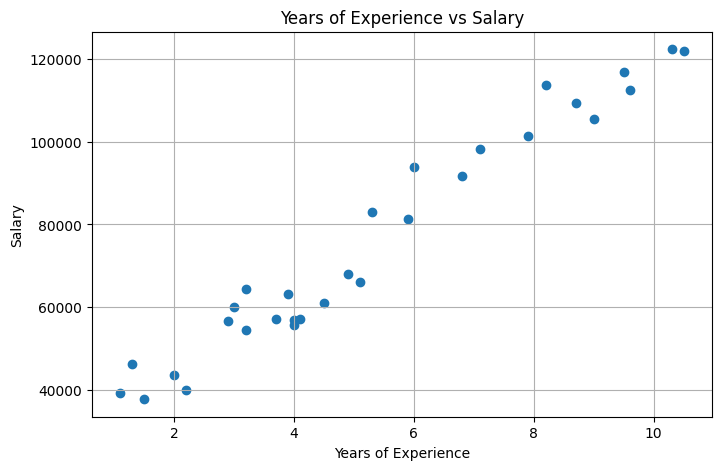

Pearson Correlation: 0.9782416184887599


In [ ]:
# Scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(df['YearsExperience'], df['Salary'])

plt.title("Years of Experience vs Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.grid(True)

plt.show()

# Pearson correlation
correlation = df['YearsExperience'].corr(df['Salary'])

print("Pearson Correlation:", correlation)

**Q3. Train-test split and reshaping**

In [ ]:
# Separate independent and dependent variables
X = df.iloc[:, 0].values
y = df.iloc[:, 1].values

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=2/3, random_state=0
)

# Reshape features
X_train = X_train.reshape(-1, 1)
X_test = X_test.reshape(-1, 1)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (20, 1)
Testing Features Shape: (10, 1)
Training Target Shape: (20,)
Testing Target Shape: (10,)


**Q4. Train Linear Regression model**

In [ ]:
# Create model
regressor = LinearRegression()

# Train model
regressor.fit(X_train, y_train)

# Display slope and intercept
print("Slope:", regressor.coef_[0])
print("Intercept:", regressor.intercept_)

# Regression equation
print("\nRegression Equation:")
print(f"Salary = {regressor.intercept_:.2f} + {regressor.coef_[0]:.2f} * YearsExperience")

Slope: 9345.942443122372
Intercept: 26816.192244031183

Regression Equation:
Salary = 26816.19 + 9345.94 * YearsExperience


**Q5. Predict salaries**

In [ ]:
# Predict salaries for test data
y_pred = regressor.predict(X_test)

print("Test Set Predictions:")

for actual, predicted in zip(y_test, y_pred):
    print("Actual:", actual, "Predicted:", round(predicted, 2))

# Predict salary for 5 and 12 years
experience = np.array([[5], [12]])

salary_prediction = regressor.predict(experience)

print("\nSalary for 5 Years:", round(salary_prediction[0], 2))
print("Salary for 12 Years:", round(salary_prediction[1], 2))

Test Set Predictions:
Actual: 37731 Predicted: 40835.11
Actual: 122391 Predicted: 123079.4
Actual: 57081 Predicted: 65134.56
Actual: 63218 Predicted: 63265.37
Actual: 116969 Predicted: 115602.65
Actual: 109431 Predicted: 108125.89
Actual: 112635 Predicted: 116537.24
Actual: 55794 Predicted: 64199.96
Actual: 83088 Predicted: 76349.69
Actual: 101302 Predicted: 100649.14

Salary for 5 Years: 73545.9
Salary for 12 Years: 138967.5


**Q6. Plot training data, testing data and regression line**

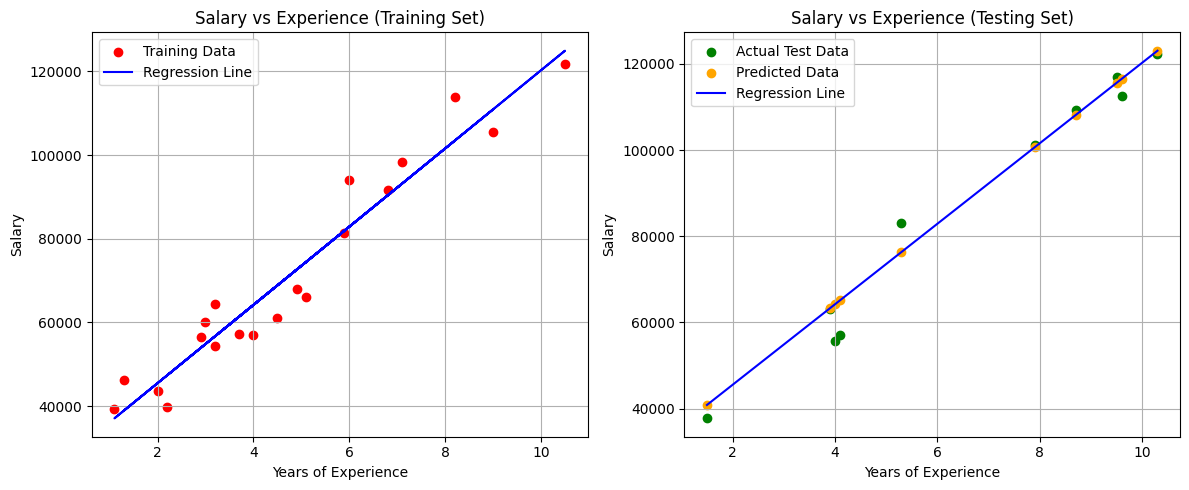

In [ ]:
plt.figure(figsize=(12, 5))

# Training data subplot
plt.subplot(1, 2, 1)

plt.scatter(X_train, y_train, color='red', label='Training Data')

plt.plot(
    X_train,
    regressor.predict(X_train),
    color='blue',
    label='Regression Line'
)

plt.title("Salary vs Experience (Training Set)")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.legend()
plt.grid(True)

# Testing data subplot
plt.subplot(1, 2, 2)

plt.scatter(X_test, y_test, color='green', label='Actual Test Data')

plt.scatter(X_test, y_pred, color='orange', label='Predicted Data')

plt.plot(
    np.sort(X_test, axis=0),
    regressor.predict(np.sort(X_test, axis=0)),
    color='blue',
    label='Regression Line'
)

plt.title("Salary vs Experience (Testing Set)")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Q7. Calculate MSE, MAE, RMSE and R²**

In [ ]:
# Custom MSE function
def calculate_mse(actual, predicted):
    return np.mean((actual - predicted) ** 2)

# Custom MAE function
def calculate_mae(actual, predicted):
    return np.mean(np.abs(actual - predicted))

# Calculate metrics
mse = calculate_mse(y_test, y_pred)
mae = calculate_mae(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Custom MSE:", mse)
print("Sklearn MSE:", mean_squared_error(y_test, y_pred))

print("\nCustom MAE:", mae)
print("Sklearn MAE:", mean_absolute_error(y_test, y_pred))

print("\nRMSE:", rmse)
print("R2 Score:", r2)

Custom MSE: 21026037.329511296
Sklearn MSE: 21026037.329511296

Custom MAE: 3426.4269374307078
Sklearn MAE: 3426.4269374307078

RMSE: 4585.4157204675885
R2 Score: 0.9749154407708353


**Q8. Residual plot**

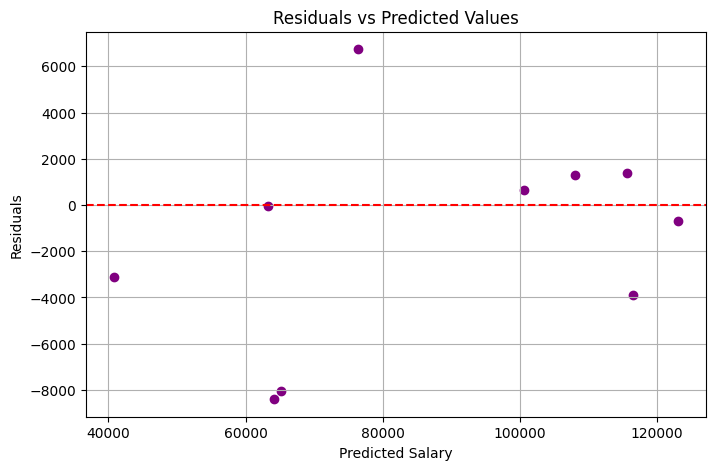

In [ ]:
# Calculate residuals
residuals = y_test - y_pred

# Plot residuals
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, color='purple')

plt.axhline(y=0, color='red', linestyle='--')

plt.title("Residuals vs Predicted Values")
plt.xlabel("Predicted Salary")
plt.ylabel("Residuals")
plt.grid(True)

plt.show()

**Q9. Implement Ordinary Least Squares (OLS) from scratch**

In [ ]:
# Convert training data into 1D arrays
x = X_train.flatten()
y_actual = y_train

# Calculate means
x_mean = np.mean(x)
y_mean = np.mean(y_actual)

# Calculate slope
b1 = np.sum((x - x_mean) * (y_actual - y_mean)) / np.sum((x - x_mean) ** 2)

# Calculate intercept
b0 = y_mean - b1 * x_mean

print("OLS From Scratch")
print("Slope:", b1)
print("Intercept:", b0)

print("\nScikit-learn Results")
print("Slope:", regressor.coef_[0])
print("Intercept:", regressor.intercept_)

OLS From Scratch
Slope: 9345.942443122376
Intercept: 26816.19224403117

Scikit-learn Results
Slope: 9345.942443122372
Intercept: 26816.192244031183


**Q10. Repeat train-test split using five random states**

In [ ]:
random_states = [0, 1, 2, 3, 4]

results = []

for state in random_states:

    X_train_rs, X_test_rs, y_train_rs, y_test_rs = train_test_split(
        X, y, train_size=2/3, random_state=state
    )

    X_train_rs = X_train_rs.reshape(-1, 1)
    X_test_rs = X_test_rs.reshape(-1, 1)

    model = LinearRegression()

    model.fit(X_train_rs, y_train_rs)

    predictions = model.predict(X_test_rs)

    score = r2_score(y_test_rs, predictions)

    results.append({
        "Random State": state,
        "R2 Score": score
    })

result_df = pd.DataFrame(results)

print(result_df)

   Random State  R2 Score
0             0  0.974915
1             1  0.924085
2             2  0.904180
3             3  0.943436
4             4  0.946808


**Part 2: Penguins Dataset – Feature Engineering**

**Step 1: Import libraries and load datasets**

**Q1. Load the dataset and report the number of missing values in each column.**

In [ ]:
import pandas as pd

# Load dataset
df = pd.read_csv("penguins_size.csv")

# Display dataset
print("First Five Rows:")
print(df.head())

# Display dataset shape
print("\nDataset Shape:", df.shape)

# Count missing values
print("\nMissing Values in Each Column:")
print(df.isnull().sum())

First Five Rows:
  species     island  culmen_length_mm  culmen_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen              39.1             18.7              181.0   
1  Adelie  Torgersen              39.5             17.4              186.0   
2  Adelie  Torgersen              40.3             18.0              195.0   
3  Adelie  Torgersen               NaN              NaN                NaN   
4  Adelie  Torgersen              36.7             19.3              193.0   

   body_mass_g     sex  
0       3750.0    MALE  
1       3800.0  FEMALE  
2       3250.0  FEMALE  
3          NaN     NaN  
4       3450.0  FEMALE  

Dataset Shape: (344, 7)

Missing Values in Each Column:
species               0
island                0
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64


**Q2. Identify invalid entries in the sex column and remove them programmatically.**

In [ ]:
# Display unique values
print("Unique values in sex column:")
print(df['sex'].unique())

# Identify invalid entries (excluding missing values)
invalid = df[
    df['sex'].notna() &
    ~df['sex'].isin(['MALE', 'FEMALE'])
]

print("\nInvalid Entries:")
print(invalid)

# Remove invalid entries
df_clean = df[
    df['sex'].isna() |
    df['sex'].isin(['MALE', 'FEMALE'])
].copy()

print("\nShape Before Cleaning:", df.shape)
print("Shape After Cleaning:", df_clean.shape)

print("\nRemaining Sex Values:")
print(df_clean['sex'].value_counts(dropna=False))

Unique values in sex column:
['MALE' 'FEMALE' nan '.']

Invalid Entries:
    species  island  culmen_length_mm  culmen_depth_mm  flipper_length_mm  \
336  Gentoo  Biscoe              44.5             15.7              217.0   

     body_mass_g sex  
336       4875.0   .  

Shape Before Cleaning: (344, 7)
Shape After Cleaning: (343, 7)

Remaining Sex Values:
sex
MALE      168
FEMALE    165
NaN        10
Name: count, dtype: int64


**3. Create three cleaned versions of the dataset.**

In [ ]:
import numpy as np

# A. Drop rows with missing values
df_drop = df_clean.dropna()

print("A. Dataset after dropping missing values:")
print(df_drop.shape)


# B. Mean and mode imputation
df_mean = df_clean.copy()

# Fill numerical columns with mean
numeric_cols = df_mean.select_dtypes(include=np.number).columns

for col in numeric_cols:
    df_mean[col] = df_mean[col].fillna(df_mean[col].mean())

# Fill sex with mode
df_mean['sex'] = df_mean['sex'].fillna(df_mean['sex'].mode()[0])

print("\nB. Dataset after mean and mode imputation:")
print(df_mean.shape)


# C. Median imputation within each species
df_median = df_clean.copy()

for col in numeric_cols:
    df_median[col] = df_median.groupby('species')[col].transform(
        lambda x: x.fillna(x.median())
    )

# Fill missing sex using mode
df_median['sex'] = df_median['sex'].fillna(
    df_median['sex'].mode()[0]
)

print("\nC. Dataset after median imputation:")
print(df_median.shape)


# Check remaining missing values
print("\nMissing values in mean-imputed dataset:")
print(df_mean.isnull().sum())

print("\nMissing values in median-imputed dataset:")
print(df_median.isnull().sum())

A. Dataset after dropping missing values:
(333, 7)

B. Dataset after mean and mode imputation:
(343, 7)

C. Dataset after median imputation:
(343, 7)

Missing values in mean-imputed dataset:
species              0
island               0
culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

Missing values in median-imputed dataset:
species              0
island               0
culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64


**Q4. Calculate mean body mass and flipper length for each species and plot a bar chart.**

Mean Body Mass and Flipper Length:
           body_mass_g  flipper_length_mm
species                                  
Adelie     3706.164384         190.102740
Chinstrap  3733.088235         195.823529
Gentoo     5092.436975         217.235294


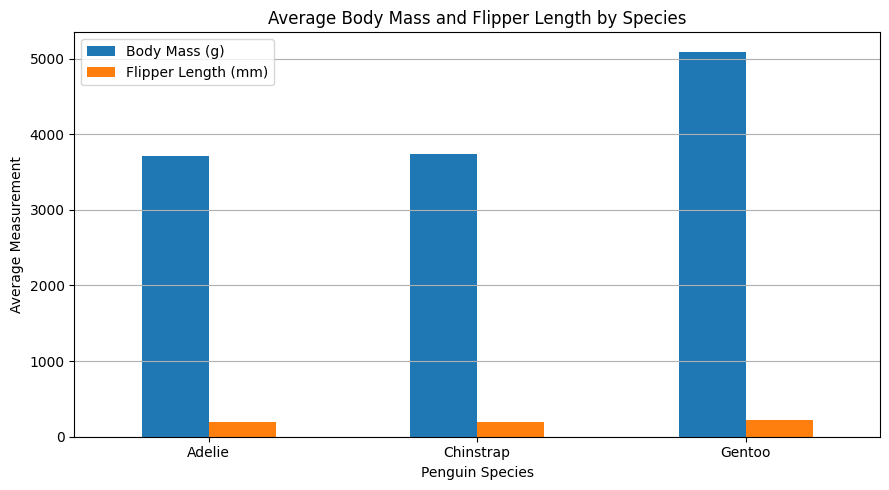

In [ ]:
import matplotlib.pyplot as plt

# Calculate species-wise mean
species_mean = df_drop.groupby('species')[
    ['body_mass_g', 'flipper_length_mm']
].mean()

print("Mean Body Mass and Flipper Length:")
print(species_mean)

# Plot bar chart
species_mean.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title("Average Body Mass and Flipper Length by Species")
plt.xlabel("Penguin Species")
plt.ylabel("Average Measurement")
plt.xticks(rotation=0)
plt.legend(["Body Mass (g)", "Flipper Length (mm)"])
plt.grid(axis='y')

plt.tight_layout()
plt.show()

**Q5. Convert categorical columns into category datatype and apply Label Encoding.**

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Create a copy
df_encoded = df_mean.copy()

# Categorical columns
cat_cols = ['species', 'island', 'sex']

# Convert to category datatype and apply cat.codes
print("Using Pandas Category Codes:")

for col in cat_cols:
    df_encoded[col] = df_encoded[col].astype('category')
    df_encoded[col + '_code'] = df_encoded[col].cat.codes

print(df_encoded[cat_cols + [
    'species_code', 'island_code', 'sex_code'
]].head())


# Using LabelEncoder
print("\nUsing LabelEncoder:")

for col in cat_cols:
    encoder = LabelEncoder()
    df_encoded[col + '_label'] = encoder.fit_transform(df_mean[col])

print(df_encoded[[
    'species_code', 'species_label',
    'island_code', 'island_label',
    'sex_code', 'sex_label'
]].head())

Using Pandas Category Codes:
  species     island     sex  species_code  island_code  sex_code
0  Adelie  Torgersen    MALE             0            2         1
1  Adelie  Torgersen  FEMALE             0            2         0
2  Adelie  Torgersen  FEMALE             0            2         0
3  Adelie  Torgersen    MALE             0            2         1
4  Adelie  Torgersen  FEMALE             0            2         0

Using LabelEncoder:
   species_code  species_label  island_code  island_label  sex_code  sex_label
0             0              0            2             2         1          1
1             0              0            2             2         0          0
2             0              0            2             2         0          0
3             0              0            2             2         1          1
4             0              0            2             2         0          0


**Q6. Apply One-Hot Encoding to island and sex using pd.get_dummies().**

In [ ]:
# Select numerical features
numeric_features = df_mean[
    ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm']
]

# One-hot encode categorical columns
encoded_features = pd.get_dummies(
    df_mean[['species', 'island', 'sex']],
    drop_first=True,
    dtype=int
)

# Combine numerical and encoded features
final_features = pd.concat(
    [numeric_features, encoded_features],
    axis=1
)

print("Final Feature Matrix:")
print(final_features.head())

print("\nFinal Feature Matrix Shape:")
print(final_features.shape)

Final Feature Matrix:
   culmen_length_mm  culmen_depth_mm  flipper_length_mm  species_Chinstrap  \
0         39.100000        18.700000         181.000000                  0   
1         39.500000        17.400000         186.000000                  0   
2         40.300000        18.000000         195.000000                  0   
3         43.920235        17.155425         200.868035                  0   
4         36.700000        19.300000         193.000000                  0   

   species_Gentoo  island_Dream  island_Torgersen  sex_MALE  
0               0             0                 1         1  
1               0             0                 1         0  
2               0             0                 1         0  
3               0             0                 1         1  
4               0             0                 1         0  

Final Feature Matrix Shape:
(343, 8)


**Q7. Apply StandardScaler and MinMaxScaler to the four numerical columns.**

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Select four numerical columns
numeric_cols = [
    'culmen_length_mm',
    'culmen_depth_mm',
    'flipper_length_mm',
    'body_mass_g'
]

# Display original statistics
print("Before Scaling:")
print(df_mean[numeric_cols].describe())

# Standard Scaling
standard_scaler = StandardScaler()

standard_data = standard_scaler.fit_transform(
    df_mean[numeric_cols]
)

standard_df = pd.DataFrame(
    standard_data,
    columns=numeric_cols
)

print("\nAfter Standard Scaling:")
print(standard_df.describe())

# MinMax Scaling
minmax_scaler = MinMaxScaler()

minmax_data = minmax_scaler.fit_transform(
    df_mean[numeric_cols]
)

minmax_df = pd.DataFrame(
    minmax_data,
    columns=numeric_cols
)

print("\nAfter MinMax Scaling:")
print(minmax_df.describe())

Before Scaling:
       culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g
count        343.000000       343.000000         343.000000   343.000000
mean          43.920235        17.155425         200.868035  4199.780059
std            5.451506         1.970337          14.014097   799.950855
min           32.100000        13.100000         172.000000  2700.000000
25%           39.250000        15.600000         190.000000  3550.000000
50%           44.100000        17.300000         197.000000  4050.000000
75%           48.500000        18.700000         213.000000  4750.000000
max           59.600000        21.500000         231.000000  6300.000000

After Standard Scaling:
       culmen_length_mm  culmen_depth_mm  flipper_length_mm   body_mass_g
count      3.430000e+02     3.430000e+02       3.430000e+02  3.430000e+02
mean      -2.485864e-16    -4.143106e-16      -3.728796e-16 -1.657243e-16
std        1.001461e+00     1.001461e+00       1.001461e+00  1.001461e+00
min   

**Q8. Build a Simple Linear Regression model to predict body mass using flipper length.**

Slope: 48.48998437453065
Intercept: -5540.291596680017

Regression Equation:
Body Mass = -5540.29 + 48.49 * Flipper Length

R2 Score: 0.7477693620715881


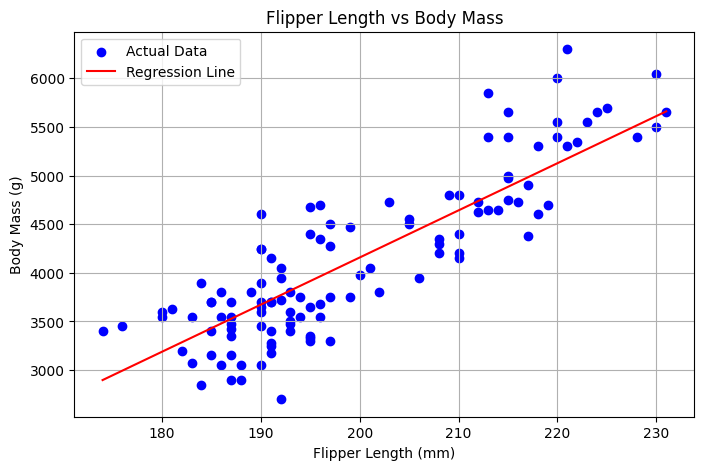

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Independent and dependent variables
X = df_mean[['flipper_length_mm']]
y = df_mean['body_mass_g']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=2/3, random_state=0
)

# Create and train model
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Display coefficients
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

print("\nRegression Equation:")
print(
    f"Body Mass = {model.intercept_:.2f} + "
    f"{model.coef_[0]:.2f} * Flipper Length"
)

# Calculate R2 score
r2 = r2_score(y_test, y_pred)

print("\nR2 Score:", r2)

# Plot regression
plt.figure(figsize=(8, 5))

plt.scatter(X_test, y_test, color='blue', label='Actual Data')
plt.plot(
    X_test.sort_values(by='flipper_length_mm'),
    model.predict(X_test.sort_values(by='flipper_length_mm')),
    color='red',
    label='Regression Line'
)

plt.title("Flipper Length vs Body Mass")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (g)")
plt.legend()
plt.grid(True)
plt.show()

**Q9. Build a Multiple Linear Regression model using all engineered features.**

In [ ]:
# Independent variables: all engineered features
X = final_features

# Dependent variable
y = df_mean['body_mass_g']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=2/3, random_state=0
)

# Create model
multiple_model = LinearRegression()

# Train model
multiple_model.fit(X_train, y_train)

# Predict values
y_pred = multiple_model.predict(X_test)

# Calculate R2 score
multiple_r2 = r2_score(y_test, y_pred)

print("Multiple Linear Regression")
print("R2 Score:", multiple_r2)

print("\nModel Coefficients:")

for feature, coefficient in zip(
    X.columns, multiple_model.coef_
):
    print(feature, ":", coefficient)

print("\nIntercept:", multiple_model.intercept_)

Multiple Linear Regression
R2 Score: 0.8493525824865509

Model Coefficients:
culmen_length_mm : 20.03117881767647
culmen_depth_mm : 67.61849835885675
flipper_length_mm : 18.804337842613556
species_Chinstrap : -258.2646366423159
species_Gentoo : 846.4578769888486
island_Dream : -72.93238972638197
island_Torgersen : -133.87945801906918
sex_MALE : 302.20966419046266

Intercept: -1990.1817299005397


**Q10. Create a 1D array of numbers 1 to 10 and demonstrate reshape(), flatten(), transpose and np.resize() to shape (3, 4).**

In [ ]:
import numpy as np

# Create 1D array
arr = np.arange(1, 11)

print("Original 1D Array:")
print(arr)

# Reshape array
reshaped = arr.reshape(2, 5)

print("\nReshaped Array (2, 5):")
print(reshaped)

# Flatten array
flattened = reshaped.flatten()

print("\nFlattened Array:")
print(flattened)

# Transpose array
transposed = reshaped.T

print("\nTransposed Array:")
print(transposed)

# Resize array to (3, 4)
resized = np.resize(arr, (3, 4))

print("\nResized Array (3, 4):")
print(resized)

Original 1D Array:
[ 1  2  3  4  5  6  7  8  9 10]

Reshaped Array (2, 5):
[[ 1  2  3  4  5]
 [ 6  7  8  9 10]]

Flattened Array:
[ 1  2  3  4  5  6  7  8  9 10]

Transposed Array:
[[ 1  6]
 [ 2  7]
 [ 3  8]
 [ 4  9]
 [ 5 10]]

Resized Array (3, 4):
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10  1  2]]


**Q11. Compute determinant, rank, trace and inverse of two matrices.**

In [ ]:
import numpy as np

# Define matrices
A = np.array([
    [1, 2, 3],
    [2, 4, 6],
    [3, 8, 9]
])

B = np.array([
    [1, 1, 3],
    [1, 2, 4],
    [1, 3, 0]
])

# Function to perform matrix operations
def matrix_operations(M, name):

    print("\n", name)
    print("Matrix:")
    print(M)

    # Determinant
    print("Determinant:", np.linalg.det(M))

    # Rank
    print("Rank:", np.linalg.matrix_rank(M))

    # Trace
    print("Trace:", np.trace(M))

    # Inverse
    try:
        inverse = np.linalg.inv(M)
        print("Inverse:")
        print(inverse)

    except np.linalg.LinAlgError:
        print("Inverse does not exist.")

# Perform operations
matrix_operations(A, "Matrix A")
matrix_operations(B, "Matrix B")


 Matrix A
Matrix:
[[1 2 3]
 [2 4 6]
 [3 8 9]]
Determinant: 0.0
Rank: 2
Trace: 14
Inverse does not exist.

 Matrix B
Matrix:
[[1 1 3]
 [1 2 4]
 [1 3 0]]
Determinant: -5.000000000000001
Rank: 3
Trace: 3
Inverse:
[[ 2.4 -1.8  0.4]
 [-0.8  0.6  0.2]
 [-0.2  0.4 -0.2]]


**Q12. Create two DataFrames of employee names and ages. Concatenate them row-wise and column-wise, sort by name, rename a column and display summary statistics.**

In [ ]:
import pandas as pd

# Create first DataFrame
df1 = pd.DataFrame({
    'Name': ['Rahul', 'Amit', 'Priya'],
    'Age': [22, 25, 21]
})

# Create second DataFrame
df2 = pd.DataFrame({
    'Name': ['Sneha', 'Rohan', 'Neha'],
    'Age': [23, 24, 22]
})

print("First DataFrame:")
print(df1)

print("\nSecond DataFrame:")
print(df2)

# Row-wise concatenation
row_concat = pd.concat([df1, df2], axis=0, ignore_index=True)

print("\nRow-wise Concatenation:")
print(row_concat)

# Column-wise concatenation
column_concat = pd.concat([df1, df2], axis=1)

print("\nColumn-wise Concatenation:")
print(column_concat)

# Sort by employee name
sorted_df = row_concat.sort_values(
    by='Name'
).reset_index(drop=True)

print("\nSorted DataFrame:")
print(sorted_df)

# Rename column
renamed_df = sorted_df.rename(
    columns={'Name': 'Employee_Name'}
)

print("\nRenamed DataFrame:")
print(renamed_df)

# Summary statistics
print("\nSummary Statistics:")
print(renamed_df.describe())

First DataFrame:
    Name  Age
0  Rahul   22
1   Amit   25
2  Priya   21

Second DataFrame:
    Name  Age
0  Sneha   23
1  Rohan   24
2   Neha   22

Row-wise Concatenation:
    Name  Age
0  Rahul   22
1   Amit   25
2  Priya   21
3  Sneha   23
4  Rohan   24
5   Neha   22

Column-wise Concatenation:
    Name  Age   Name  Age
0  Rahul   22  Sneha   23
1   Amit   25  Rohan   24
2  Priya   21   Neha   22

Sorted DataFrame:
    Name  Age
0   Amit   25
1   Neha   22
2  Priya   21
3  Rahul   22
4  Rohan   24
5  Sneha   23

Renamed DataFrame:
  Employee_Name  Age
0          Amit   25
1          Neha   22
2         Priya   21
3         Rahul   22
4         Rohan   24
5         Sneha   23

Summary Statistics:
             Age
count   6.000000
mean   22.833333
std     1.471960
min    21.000000
25%    22.000000
50%    22.500000
75%    23.750000
max    25.000000


**Conclusion: Dataset 2**

In this practical, the Penguins dataset was successfully preprocessed by identifying and removing invalid entries and handling missing values using dropna(), mean, median and mode imputation. Categorical variables were converted using Label Encoding and One-Hot Encoding. Numerical features were scaled using StandardScaler and MinMaxScaler. Simple and Multiple Linear Regression models were implemented to predict penguin body mass. The Multiple Linear Regression model achieved a higher R² score of approximately 0.8494 compared to 0.7478 for Simple Linear Regression.